In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parents[0]  # noqa: E402
sys.path.insert(0, str(PROJECT_ROOT))  # noqa: E402

from src.lib.BasicStripWithGrid import BasicStripWithGrid
from src.lib.StripSample import StripSample

from src.lib.logistic4pl import *
from src.ML.ml_inference import *

import numpy as np
import pandas as pd

import os

2026-10-18 03:32:34.552263: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-18 03:32:34.552292: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-18 03:32:34.553318: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-18 03:32:34.559545: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Using TensorFlow backend


### Define variables and constants

In [2]:
img_conc_csv = "../data/Figure6/img_conc.csv"
best_fold_path = "../saved_mdl/detect_yolo_xs/yolo_kfold_4.h5"

FALLBACK_DETECTION_METHOD = "grid_relative"

### Read the csv and check if all image files exist

In [3]:
# Read the CSV
df = pd.read_csv(img_conc_csv)

# Sort: concentration0 descending, filename ascending
df_sorted = df.sort_values(by=["concentration0", "filename"], ascending=[False, True])

# Optional: reset index after sorting
df_sorted = df_sorted.reset_index(drop=True)

print(df_sorted)

            filename  concentration0  concentration1
0   Figure5-n1-1.png        1000.000        100000.0
1   Figure5-n2-1.png        1000.000        100000.0
2   Figure5-n3-1.png        1000.000        100000.0
3   Figure5-n1-2.png         200.000         20000.0
4   Figure5-n2-2.png         200.000         20000.0
5   Figure5-n3-2.png         200.000         20000.0
6   Figure5-n1-3.png          40.000          4000.0
7   Figure5-n2-3.png          40.000          4000.0
8   Figure5-n3-3.png          40.000          4000.0
9   Figure5-n1-4.png           8.000           800.0
10  Figure5-n2-4.png           8.000           800.0
11  Figure5-n3-4.png           8.000           800.0
12  Figure5-n1-5.png           1.600           160.0
13  Figure5-n2-5.png           1.600           160.0
14  Figure5-n3-5.png           1.600           160.0
15  Figure5-n1-6.png           0.320            32.0
16  Figure5-n2-6.png           0.320            32.0
17  Figure5-n3-6.png           0.320          

In [4]:
# Get the path for the base directory
base_dir = os.path.dirname(img_conc_csv)

# Check the first column to see if all files exist and unique
file_list = df_sorted["filename"].tolist()

if len(file_list) != len(set(file_list)):
    raise ValueError("Filenames are not unique in the CSV file.")

for img_filename in file_list:
    file_path = os.path.join(base_dir, img_filename)
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"File does not exist: {file_path}")
    else:
        print(f"File exists: {file_path}")

File exists: ../data/Figure5/Figure5-n1-1.png
File exists: ../data/Figure5/Figure5-n2-1.png
File exists: ../data/Figure5/Figure5-n3-1.png
File exists: ../data/Figure5/Figure5-n1-2.png
File exists: ../data/Figure5/Figure5-n2-2.png
File exists: ../data/Figure5/Figure5-n3-2.png
File exists: ../data/Figure5/Figure5-n1-3.png
File exists: ../data/Figure5/Figure5-n2-3.png
File exists: ../data/Figure5/Figure5-n3-3.png
File exists: ../data/Figure5/Figure5-n1-4.png
File exists: ../data/Figure5/Figure5-n2-4.png
File exists: ../data/Figure5/Figure5-n3-4.png
File exists: ../data/Figure5/Figure5-n1-5.png
File exists: ../data/Figure5/Figure5-n2-5.png
File exists: ../data/Figure5/Figure5-n3-5.png
File exists: ../data/Figure5/Figure5-n1-6.png
File exists: ../data/Figure5/Figure5-n2-6.png
File exists: ../data/Figure5/Figure5-n3-6.png
File exists: ../data/Figure5/Figure5-n1-7.png
File exists: ../data/Figure5/Figure5-n2-7.png
File exists: ../data/Figure5/Figure5-n3-7.png
File exists: ../data/Figure5/Figur

### Identify individual concentration sets (i.e. concentration0, concentration1)

In [5]:
grouped_conc_df = df.groupby(["concentration0", "concentration1"])["filename"].apply(
    list
)
print(grouped_conc_df)

concentration0  concentration1
0.000           0.0               [Figure5-n1-8.png, Figure5-n2-8.png, Figure5-n...
0.064           6.4               [Figure5-n1-7.png, Figure5-n2-7.png, Figure5-n...
0.320           32.0              [Figure5-n1-6.png, Figure5-n2-6.png, Figure5-n...
1.600           160.0             [Figure5-n1-5.png, Figure5-n2-5.png, Figure5-n...
8.000           800.0             [Figure5-n1-4.png, Figure5-n2-4.png, Figure5-n...
40.000          4000.0            [Figure5-n1-3.png, Figure5-n2-3.png, Figure5-n...
200.000         20000.0           [Figure5-n1-2.png, Figure5-n2-2.png, Figure5-n...
1000.000        100000.0          [Figure5-n1-1.png, Figure5-n2-1.png, Figure5-n...
Name: filename, dtype: object


## Load ML model

In [6]:
cur_yolo_mdl = None
cur_yolo_mdl = load_model_h5_tf(
    cur_yolo_mdl,
    class_ids,
    best_fold_path,
)

2026-10-18 03:32:38.171246: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22446 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:01:00.0, compute capability: 8.6


### For each row, create a StripSample object

In [7]:
strip_sample_ls = []
for (conc0, conc1), filenames in grouped_conc_df.items():
    print(f"Processing concentration pair: ({conc0}, {conc1}) with files: {filenames}")

    strip_sample = StripSample(
        {0: conc0, 1: conc1}, 
        fallback_detection_method=FALLBACK_DETECTION_METHOD,
        ml_mdl=cur_yolo_mdl
    )

    for img_filename in filenames:
        img_file_path = os.path.join(base_dir, img_filename)

        strip_sample.create_add_basic_strip(
            img_file_path,
        )

    strip_sample_ls.append(strip_sample)

Processing concentration pair: (0.0, 0.0) with files: ['Figure5-n1-8.png', 'Figure5-n2-8.png', 'Figure5-n3-8.png']
Processing concentration pair: (0.064, 6.4) with files: ['Figure5-n1-7.png', 'Figure5-n2-7.png', 'Figure5-n3-7.png']
Processing concentration pair: (0.32, 32.0) with files: ['Figure5-n1-6.png', 'Figure5-n2-6.png', 'Figure5-n3-6.png']
Processing concentration pair: (1.6, 160.0) with files: ['Figure5-n1-5.png', 'Figure5-n2-5.png', 'Figure5-n3-5.png']
Processing concentration pair: (8.0, 800.0) with files: ['Figure5-n1-4.png', 'Figure5-n2-4.png', 'Figure5-n3-4.png']
Processing concentration pair: (40.0, 4000.0) with files: ['Figure5-n1-3.png', 'Figure5-n2-3.png', 'Figure5-n3-3.png']
Processing concentration pair: (200.0, 20000.0) with files: ['Figure5-n1-2.png', 'Figure5-n2-2.png', 'Figure5-n3-2.png']
Processing concentration pair: (1000.0, 100000.0) with files: ['Figure5-n1-1.png', 'Figure5-n2-1.png', 'Figure5-n3-1.png']


## Start finding the peaks

In [8]:
for ss in strip_sample_ls:
    print(
        f"StripSample with concentrations: {ss.concentration} has {ss.get_num_strips()} strips."
    )

    ss.run_find_peak_area_all_strips_ml(debug=False)

StripSample with concentrations: {0: 0.0, 1: 0.0} has 3 strips.
Image loaded: ../data/Figure5/Figure5-n1-8.png with shape (537, 108)


2026-10-18 03:32:46.590909: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8906


1/1 [==============================] - 8s 8s/step
[[ 20.746233  20.355703  88.2387   422.87653 ]]
[[  0.       457.24496  105.66708    9.018707]]
Figure5-n1-8.png --- Detected grid at (0, 452, 68, 19) using ML.
Protein boxes: []
RNA boxes: [[ 21.945665 206.5096    64.09727   19.998459]]
Figure5-n1-8.png --- Estimated Protein band at (0, 292, 68, 79) using ML estimation.
Using ML detection results for Figure5-n1-8.png
[band 0] peak at x=222, Estimated peak width = 10.215728451725699lb=198, rb=234, prom=16.006, width=36 vs wlen=49 
[band 1] peak at x=326, Estimated peak width = 7.64519467282123lb=317, rb=346, prom=1.658, width=29 vs wlen=50 
[grid] peak at x=459, Estimated peak width = 6.665727291472301lb=456, rb=465, prom=51.671, width=9 vs wlen=19 
Figure5-n1-8.png --- [band 0] Peak area: 182.400
Figure5-n1-8.png --- [band 1] Peak area: 31.083

Completed peak area calculation for all strips in the sample with ML + fallback method.
Image loaded: ../data/Figure5/Figure5-n2-8.png with sha

In [9]:
true_conc0 = []
observed_peak_areas0 = []

true_conc1 = []
observed_peak_areas1 = []

for ss in strip_sample_ls:
    ss_normalized_peak_areas_xbnds = ss.get_normalized_peak_areas_across_bands()
    ss_concentration = ss.get_concentration()

    for band_id, area_list in ss_normalized_peak_areas_xbnds.items():
        has_added_conc = False

        if band_id == 0:
            true_conc0.append(ss_concentration[band_id])
            observed_peak_areas0.append(area_list)
        elif band_id == 1:
            true_conc1.append(ss_concentration[band_id])
            observed_peak_areas1.append(area_list)


In [10]:
observed_peak_areas0 = np.array(observed_peak_areas0)
true_conc0 = np.array(true_conc0)

observed_peak_areas1 = np.array(observed_peak_areas1)
true_conc1 = np.array(true_conc1)

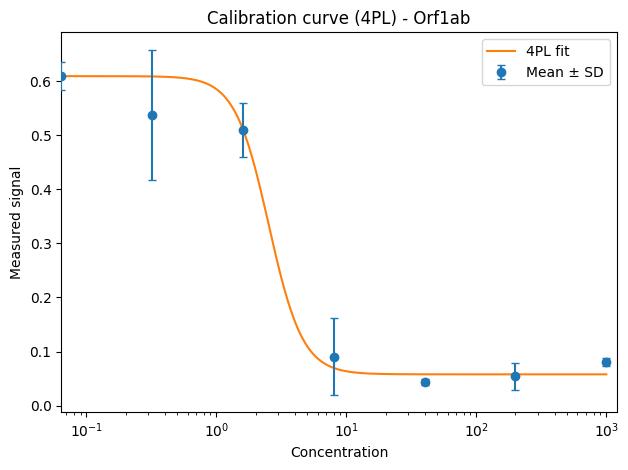

In [11]:
popt0, pcov0, info0 = fit_logistic4pl(true_conc0, observed_peak_areas0)


plt_4pl_curve(true_conc0, observed_peak_areas0, popt0, include_x_zero=False, title_suffix=" - Orf1ab")

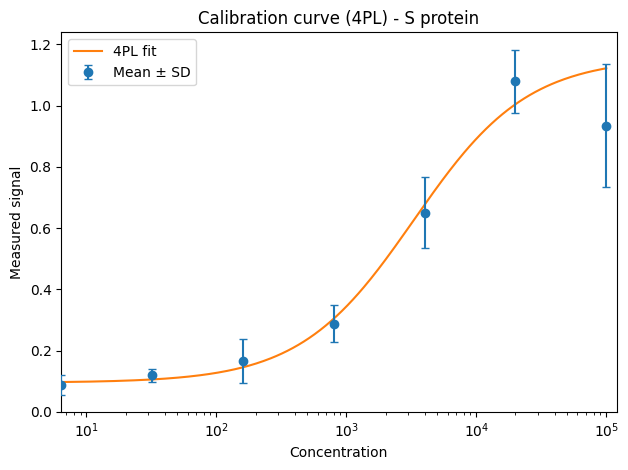

In [12]:
popt1, pcov1, info1 = fit_logistic4pl(true_conc1, observed_peak_areas1)


plt_4pl_curve(true_conc1, observed_peak_areas1, popt1, include_x_zero=False, title_suffix=" - S protein")

### Export for graphpad

In [13]:
df_obs, df_curve = export_calibration_for_graphpad(true_conc0, observed_peak_areas0, popt0, include_x_zero=False, out_path="../saved_mdl/4pl", out_prefix="Orf1ab_4pl")

In [14]:
df_obs, df_curve = export_calibration_for_graphpad(true_conc1, observed_peak_areas1, popt1, include_x_zero=False, out_path="../saved_mdl/4pl", out_prefix="SProtein_4pl")